# Intelligent Agents: Reflex-Based Agents for GridHunt

Student Name: [Add your name]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]

## Learning Outcomes

* Apply core AI concepts by implementing the agent function for a simple and model-based reflex agents that respond to environmental percepts.
* Practice how the environment and the agent function interact.
* Analyze agent performance through controlled experiments across different environment configurations.

## Instructions

Total Points: Undergrads 10

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook.
### AI Use

Here are some guidelines that will make it easier for you:

* __Don't:__ Rely on AI auto completion. You will waste a lot of time trying to figure out how the suggested code relates to what we do in class. Turn off AI code completion (e.g., Copilot) in your IDE.
* __Don't:__ Do not submit code/text that you do not understand or have not checked to make sure that it is complete and correct.
* __Do:__ Use AI for debugging and letting it explain code and concepts from class.

## Introduction

![GridHunt Image](gridhunt.png)

Gridhunt is a small educational game that helps you practice implementing simple agent functions. It is a modified Python reimplementation of Gridhunt2. 

The objective of gridhunt is to implement an intelligent agent, the hunter, who can catch a monster faster than all other hunters. Gridhunt uses a $n \times n$ arena consisting of a grid of tiles. Gridhunt is a turn-based game, and the hunter and the monster move on this grid. A hunter catches the monster if she/he moves on the same square the monster currently occupies. If the monster survives the maximum number of steps for the game, then the monster wins.

## PEAS Description of Gridhunt

__Performance Measure:__ The performance is measured as the number of steps the hunter uses to catch the monster. Catching the monster means to be on the same square.

__Environment:__ An arena with $n \times n$ squares. At the beginning the monster and the hunter are randomly placed in the arena environment. The hunter and the monster
    can move around, but cannot leave the arena.

__Actuators:__ The agent can move to an adjacent square using actions "north", "east", "west", and "south", or teleport which will move the agent 
    to a random square in the arena.

__Sensors:__ The agent can always see its location in the arena but only gets the monster location when it stops and listens.

## The Arena Environment

The environment manages the location of the agents (hunter and monster). It initially places them in a random location and then provides them in every step with percepts (the location of the hunter and the monster) and asks them for their action. 

__A Note on positions:__
The arena is implemented as an array with row and column indices representing the position.
Positions are stored in a numpy array where `pos[0]` is the row index and `pos[1]` is the column index in the arena. North means up in this array, that is the row index gets smaller when going north. Remember indices in Python start with 0 and go to `n-1`.

In [72]:
import numpy as np
from IPython.display import clear_output
from time import sleep

def arena_environment(hunter_agent_function, 
                      monster_agent_function, 
                      n = 30, max_steps = 100, 
                      visualize = False, animation = False):
    """
    Simulate an arena where a hunter agent tries to catch a monster agent.

    Parameters:
    hunter_agent_function (function): A function that takes the current positions of the hunter and monster
                                      and returns the next move for the hunter ('north', 'east', 'west', 'south', 'teleport').
    monster_agent_function (function): A function that takes the current positions of the hunter and monster
                                       and returns the next move for the monster (or 'stay' to remain in place).
    n (int): The size of the arena (n x n grid).
    max_steps (int): The maximum number of steps to simulate.
    visualize (bool): Whether to visualize the arena.
    animation (bool): Whether to animate the visualization with a delay.

    Returns:
    int: The number of steps taken for the hunter to catch the monster or np.nan (not a number) if not caught.
    """
    
    # Initialize positions
    monster_pos = np.random.randint(0, n-1, size=2)
    hunter_pos = np.random.randint(0, n-1, size=2)
    
    def move(action, position):
        """calculate new position for the agent."""
        if action == 'north':
            position[0] -= 1
        elif action == 'south':
            position[0] += 1
        elif action == 'west':
            position[1] -= 1
        elif action == 'east':
            position[1] += 1
        else:
            raise ValueError("Invalid action.")
        
        # Ensure position stays within bounds
        position = np.clip(position, 0, n-1)
        return position

    def print_arena():

        if animation:
            sleep(1)
            clear_output(wait=True)
        print(f"Step {step+1}: Hunter is at '{hunter_pos}'; Monster is at '{monster_pos}'")
        arena = np.full((n, n), '.', dtype=str)
        arena[monster_pos[0], monster_pos[1]] = 'M'
        arena[hunter_pos[0], hunter_pos[1]] = 'H'
        if np.array_equal(hunter_pos, monster_pos):
            arena[monster_pos[0], monster_pos[1]] = '*'
        print("\n".join("".join(row) for row in arena))

    # run the environment
    hunter_action = None  # Initialize hunter_action to None for the first step
    for step in range(max_steps):
        if visualize:
            print_arena()
        
        # Check if hunter has caught the monster
        if np.array_equal(hunter_pos, monster_pos):
            if visualize:
                print(f"Hunter caught the monster in {step} steps!")
            return step
        
        # Get next move from monster agent function
        monster_action = monster_agent_function(hunter_pos, monster_pos)
        
        if monster_action != 'stay':
            monster_pos = move(monster_action, monster_pos)

        # Get next move from hunter agent function. The monster's position is only provided 
        # if the hunter chose 'listen' as the previous action.
        if hunter_action == 'listen':
            monster_pos_instrument = monster_pos
        else: 
            monster_pos_instrument = None
        
        hunter_action = hunter_agent_function(hunter_pos, monster_pos_instrument)
        
        if hunter_action == 'listen':
            pass
        elif hunter_action == 'teleport':
            hunter_pos = np.random.randint(0, n-1, size=2)
        else:
            hunter_pos = move(hunter_action, hunter_pos)
    
        # print the agents' actions
        if visualize:
            print(f"Hunter chose action '{hunter_action}'")
            print(f"Monster chose action '{monster_action}'")
            print("\n")

    # the hunter failed to catch the monster within max_steps
    if visualize:
        print(f"Hunter failed to catch the monster in {max_steps} steps.")
    
    return np.nan

I implement the monster here as a simple agent that moves around randomly, but mostly stays in its place. You can use AI to get a detailed explanation of how the following code works.

In [73]:
monster_actions = ["north", "east", "west", "south", "stay"]

def monster_agent_function_simple(hunter_pos, monster_pos):
    return np.random.choice(monster_actions, p=[0.125, 0.125, 0.125, 0.125, 0.5])

# The Hunter Agent

Your job is to implement a simple-reflex hunter agent that can catch the monster. Remember, your agent is implemented as an agent function that get percepts and needs to return a valid action. The actions are: 

In [74]:
actions = ["north", "east", "west", "south", "teleport", "listen"]

## A Simple Example Implementation

Here is a very simple hunter that just runs around randomly and hopes that it bumps into the monster. 

In [75]:
def simple_randomized_hunter_agent_function(hunter_location, monster_location):
    return np.random.choice(actions)

Ask the agent for an action.

In [76]:
simple_randomized_hunter_agent_function([0,0], None)

np.str_('west')

## Experimenting With the Agent

We can place the monster and the hunter into the environment and run a simulation by calling the environment function.

In [77]:
arena_environment(simple_randomized_hunter_agent_function, 
                  monster_agent_function_simple, 
                  n=5, max_steps=10, visualize=True, animation=False)

Step 1: Hunter is at '[1 0]'; Monster is at '[1 2]'
.....
H.M..
.....
.....
.....
Hunter chose action 'teleport'
Monster chose action 'stay'


Step 2: Hunter is at '[0 0]'; Monster is at '[1 2]'
H....
..M..
.....
.....
.....
Hunter chose action 'east'
Monster chose action 'west'


Step 3: Hunter is at '[0 1]'; Monster is at '[1 1]'
.H...
.M...
.....
.....
.....
Hunter chose action 'east'
Monster chose action 'west'


Step 4: Hunter is at '[0 2]'; Monster is at '[1 0]'
..H..
M....
.....
.....
.....
Hunter chose action 'west'
Monster chose action 'east'


Step 5: Hunter is at '[0 1]'; Monster is at '[1 1]'
.H...
.M...
.....
.....
.....
Hunter chose action 'south'
Monster chose action 'stay'


Step 6: Hunter is at '[1 1]'; Monster is at '[1 1]'
.....
.*...
.....
.....
.....
Hunter caught the monster in 5 steps!


5

**Note for VS Code:** View as scrollable element to see the complete output.

Well, this was one run, maybe it was just good or bad luck this time!

Let's run an experiment with 100 runs in a $10 \times 10$ arena.  

In [78]:
steps = [arena_environment(simple_randomized_hunter_agent_function, monster_agent_function_simple, n=10, max_steps=100, visualize=False) for _ in range(100)] 
print(steps)

[26, 22, 55, 45, 63, nan, 81, 13, nan, nan, 73, 57, nan, nan, 36, 48, nan, nan, 66, nan, 67, nan, 20, nan, 74, nan, 94, nan, 4, 12, 79, nan, nan, nan, nan, 28, 96, nan, nan, 74, nan, nan, nan, 8, nan, 88, nan, 64, nan, 7, nan, nan, 39, nan, nan, 73, nan, nan, 45, nan, 31, 0, 12, 64, nan, nan, 47, 91, nan, nan, nan, 94, nan, nan, nan, 63, 68, nan, nan, nan, nan, 40, 8, nan, nan, 7, 53, nan, 69, nan, 2, 47, 44, 77, nan, 99, nan, nan, nan, nan]


We just got a list with the number of steps to catch the monster for 100 simulation runs.
Let's analysis the results. `nan` means that the hunter was not able to catch the monster. How many times did that happen? To answer how well the hunter did when it caught the monster, we just average the numbers that are not `nan`. 

In [79]:
print (f"Hunter failed {np.sum(np.isnan(steps))} times.")
print (f"Average steps to catch the monster over {np.sum(~np.isnan(steps))} successful runs: {round(np.nanmean(steps), 2)}")

Hunter failed 52 times.
Average steps to catch the monster over 48 successful runs: 49.44


This in not a very good agent. You need to implement a better agent function.

# Your Agent Implementation [4 points]

Write a new hunter agent function that chases the monster. Copy the simple randomized hunter function from above and make it into a model-based reflex agent. It should use listen to get the monster's location and then move towards the monster. To do that it needs to remember the monster's location. This memory makes it model-based. Here is HOWTO: How to Store State Information in the Agent.

In [80]:
def model_based_hunter(hunter_location, monster_location):
    """
    Model-based reflex hunter using Listen-Track-Chase strategy:
    - When monster_location is perceived (after listen), stores target in memory.
    - If memory is empty, executes 'listen' to acquire target coordinates.
    - If hunter reaches the remembered location but monster moved, resets memory and listens again.
    - Otherwise, moves along the axis with the largest coordinate difference toward target.
    """
    if not hasattr(model_based_hunter, 'memory'):
        model_based_hunter.memory = None

    # Step 1: Update internal model/memory if sensor provides target location
    if monster_location is not None:
        model_based_hunter.memory = [int(monster_location[0]), int(monster_location[1])]

    # Step 2: If no location is known, listen
    if model_based_hunter.memory is None:
        return 'listen'

    hr, hc = int(hunter_location[0]), int(hunter_location[1])
    mr, mc = model_based_hunter.memory[0], model_based_hunter.memory[1]

    row_diff = mr - hr
    col_diff = mc - hc

    # Step 3: Arrived at remembered spot, but monster moved away -> reset & listen
    if row_diff == 0 and col_diff == 0:
        model_based_hunter.memory = None
        return 'listen'

    # Step 4: Move along dominant axis to reduce Manhattan distance
    if abs(row_diff) >= abs(col_diff):
        return 'south' if row_diff > 0 else 'north'
    else:
        return 'east' if col_diff > 0 else 'west'

def reset_hunter():
    model_based_hunter.memory = None

model_based_hunter.reset = reset_hunter

# Quick demo of model_based_hunter in 10x10 arena
np.random.seed(42)
print('=== Demo: Model-Based Hunter in 10x10 Arena ===')
demo_steps = arena_environment(model_based_hunter, monster_agent_function_simple, n=10, max_steps=30, visualize=True)
print(f'Hunter completed hunt in {demo_steps} steps.')


=== Demo: Model-Based Hunter in 10x10 Arena ===
Step 1: Hunter is at '[7 4]'; Monster is at '[6 3]'
..........
..........
..........
..........
..........
..........
...M......
....H.....
..........
..........
Hunter chose action 'listen'
Monster chose action 'east'


Step 2: Hunter is at '[7 4]'; Monster is at '[6 4]'
..........
..........
..........
..........
..........
..........
....M.....
....H.....
..........
..........
Hunter chose action 'north'
Monster chose action 'east'


Step 3: Hunter is at '[6 4]'; Monster is at '[6 5]'
..........
..........
..........
..........
..........
..........
....HM....
..........
..........
..........
Hunter chose action 'east'
Monster chose action 'north'


Step 4: Hunter is at '[6 5]'; Monster is at '[5 5]'
..........
..........
..........
..........
..........
.....M....
.....H....
..........
..........
..........
Hunter chose action 'listen'
Monster chose action 'stay'


Step 5: Hunter is at '[6 5]'; Monster is at '[5 5]'
..........
.......

# Your Experiments [2 points]

Copy the simulation code from above and run experiments with your agent. 
Experiment with larger arenas of at least size $30 \times 30$.

Running comparative simulation (100 runs per configuration)...

--- Testing Arena Size 10x10 ---
Random Hunter     : Success =  86.0% | Avg Steps (when caught) = 101.58 (std=83.51)
Model-Based Hunter: Success = 100.0% | Avg Steps (when caught) =   8.98 (std= 4.68)

--- Testing Arena Size 30x30 ---
Random Hunter     : Success =  28.0% | Avg Steps (when caught) = 138.29 (std=86.60)
Model-Based Hunter: Success = 100.0% | Avg Steps (when caught) =  24.85 (std=12.69)

--- Testing Arena Size 50x50 ---
Random Hunter     : Success =   7.0% | Avg Steps (when caught) = 111.29 (std=72.67)
Model-Based Hunter: Success = 100.0% | Avg Steps (when caught) =  41.22 (std=18.44)

Arena Size   | Random Hunter                | Model-Based Hunter          
             | Success Rate  Avg Steps      | Success Rate  Avg Steps     
---------------------------------------------------------------------------
10x10        |        86.0%   101.58         |       100.0%   8.98          
30x30        |        28.0%

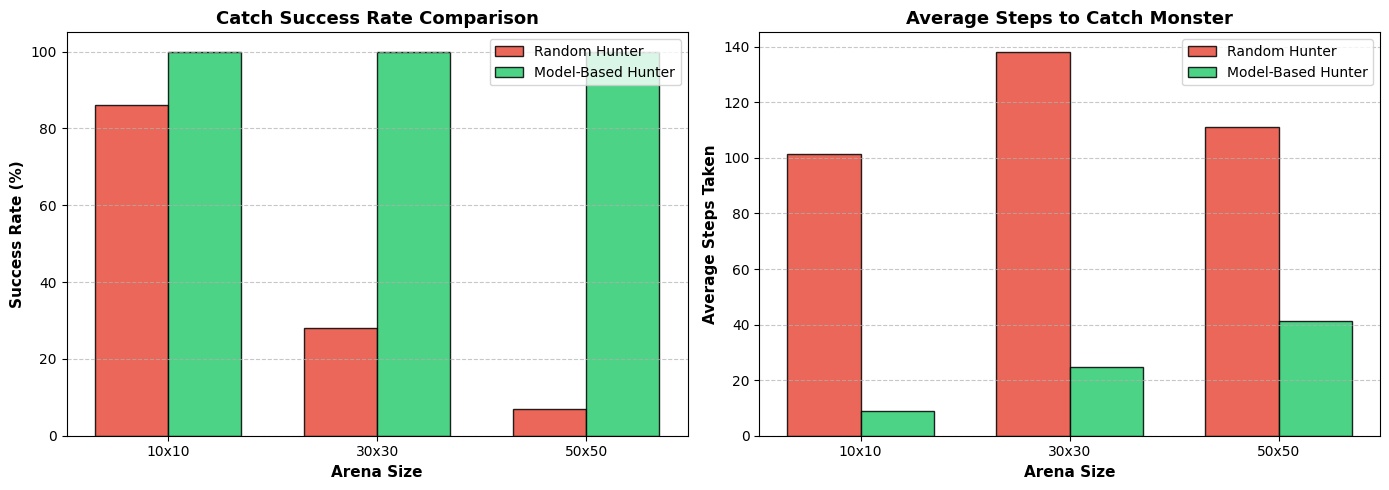

In [81]:
import numpy as np
import matplotlib.pyplot as plt

arena_sizes = [10, 30, 50]
num_trials = 100
max_steps = 300

results = {
    'size': [],
    'random_success_rate': [],
    'random_avg_steps': [],
    'model_success_rate': [],
    'model_avg_steps': []
}

print(f'Running comparative simulation ({num_trials} runs per configuration)...')

for n in arena_sizes:
    print(f'\n--- Testing Arena Size {n}x{n} ---')
    
    # 1. Simple Randomized Hunter
    rand_steps = [
        arena_environment(simple_randomized_hunter_agent_function, monster_agent_function_simple, n=n, max_steps=max_steps, visualize=False)
        for _ in range(num_trials)
    ]
    rand_success = [s for s in rand_steps if not np.isnan(s)]
    rand_succ_rate = len(rand_success) / num_trials * 100.0
    rand_mean_steps = np.mean(rand_success) if rand_success else np.nan
    rand_std_steps = np.std(rand_success) if rand_success else np.nan
    
    # 2. Model-Based Hunter
    mb_steps = []
    for _ in range(num_trials):
        model_based_hunter.reset()
        s = arena_environment(model_based_hunter, monster_agent_function_simple, n=n, max_steps=max_steps, visualize=False)
        mb_steps.append(s)
    mb_success = [s for s in mb_steps if not np.isnan(s)]
    mb_succ_rate = len(mb_success) / num_trials * 100.0
    mb_mean_steps = np.mean(mb_success) if mb_success else np.nan
    mb_std_steps = np.std(mb_success) if mb_success else np.nan
    
    results['size'].append(f'{n}x{n}')
    results['random_success_rate'].append(rand_succ_rate)
    results['random_avg_steps'].append(rand_mean_steps)
    results['model_success_rate'].append(mb_succ_rate)
    results['model_avg_steps'].append(mb_mean_steps)
    
    print(f'Random Hunter     : Success = {rand_succ_rate:5.1f}% | Avg Steps (when caught) = {rand_mean_steps:6.2f} (std={rand_std_steps:5.2f})')
    print(f'Model-Based Hunter: Success = {mb_succ_rate:5.1f}% | Avg Steps (when caught) = {mb_mean_steps:6.2f} (std={mb_std_steps:5.2f})')

# Print Summary Table
print('\n' + '='*75)
print(f"{'Arena Size':<12} | {'Random Hunter':<28} | {'Model-Based Hunter':<28}")
print(f"{'':<12} | {'Success Rate':<13} {'Avg Steps':<14} | {'Success Rate':<13} {'Avg Steps':<14}")
print('-'*75)
for i in range(len(arena_sizes)):
    r_avg = f"{results['random_avg_steps'][i]:.2f}" if not np.isnan(results['random_avg_steps'][i]) else 'N/A'
    m_avg = f"{results['model_avg_steps'][i]:.2f}" if not np.isnan(results['model_avg_steps'][i]) else 'N/A'
    print(f"{results['size'][i]:<12} | {results['random_success_rate'][i]:>11.1f}%   {r_avg:<14} | {results['model_success_rate'][i]:>11.1f}%   {m_avg:<14}")
print('='*75)

# Visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

x = np.arange(len(arena_sizes))
width = 0.35

# Plot 1: Success Rate
ax1.bar(x - width/2, results['random_success_rate'], width, label='Random Hunter', color='#e74c3c', alpha=0.85, edgecolor='black')
ax1.bar(x + width/2, results['model_success_rate'], width, label='Model-Based Hunter', color='#2ecc71', alpha=0.85, edgecolor='black')
ax1.set_xlabel('Arena Size', fontweight='bold', fontsize=11)
ax1.set_ylabel('Success Rate (%)', fontweight='bold', fontsize=11)
ax1.set_title('Catch Success Rate Comparison', fontweight='bold', fontsize=13)
ax1.set_xticks(x)
ax1.set_xticklabels(results['size'])
ax1.set_ylim(0, 105)
ax1.grid(axis='y', linestyle='--', alpha=0.7)
ax1.legend()

# Plot 2: Average Steps
rand_plot_avg = [0 if np.isnan(v) else v for v in results['random_avg_steps']]
ax2.bar(x - width/2, rand_plot_avg, width, label='Random Hunter', color='#e74c3c', alpha=0.85, edgecolor='black')
ax2.bar(x + width/2, results['model_avg_steps'], width, label='Model-Based Hunter', color='#2ecc71', alpha=0.85, edgecolor='black')
ax2.set_xlabel('Arena Size', fontweight='bold', fontsize=11)
ax2.set_ylabel('Average Steps Taken', fontweight='bold', fontsize=11)
ax2.set_title('Average Steps to Catch Monster', fontweight='bold', fontsize=13)
ax2.set_xticks(x)
ax2.set_xticklabels(results['size'])
ax2.grid(axis='y', linestyle='--', alpha=0.7)
ax2.legend()

plt.tight_layout()
plt.show()


## Your Conclusion [4 points] 

Discuss the following:

* What is your hunter's final strategy to choose actions. Why does it work well?
* Do you use teleportation. Why and in what situation? Why not?
* How does the arena size affects your hunter agent's performance?

### Hunter Strategy Discussion

#### 1. Hunter's Action Selection Strategy & Why It Works
The agent implements a **Listen-Track-Chase** model-based reflex strategy:
- **Information Acquisition (`listen`):** Whenever the monster's location is unknown (`memory is None`), the agent elects to `listen`. This consumes one turn but yields the exact grid coordinates of the monster.
- **Internal State Representation (`memory`):** The hunter stores `[monster_row, monster_col]` into persistent memory, transitioning from an unguided reflex agent into a model-based agent with an internal target representation.
- **Directional Pursuit (`chase`):** The hunter calculates the row difference $\Delta r = m_r - h_r$ and column difference $\Delta c = m_c - h_c$. By greedily stepping along the axis with the greater coordinate difference, the agent guarantees a reduction of Manhattan distance by 1 unit on every step.
- **Adaptive Target Re-evaluation:** If the hunter reaches the remembered location $(h_r == m_r, h_c == m_c)$ but the monster has moved to an adjacent square, the hunter immediately invalidates its stale memory (`memory = None`) and issues a `listen` command to update the monster's new coordinates.
- **Why it works so well:** The monster moves randomly and stays stationary 50% of the time (`p=[0.125, 0.125, 0.125, 0.125, 0.5]`). This low mobility allows the direct pursuit vector to rapidly close the distance without overshooting.

#### 2. Use of Teleportation: Why Not?
- **We do NOT use teleportation.**
- **Rationale:** Teleportation relocates the hunter to a uniformly random cell $\text{Uniform}(0, n-1) \times \text{Uniform}(0, n-1)$. In expectation, random teleportation places the hunter at an average Manhattan distance of $\approx \frac{2}{3}n$ from the monster. If the hunter is currently chasing the monster or within a reasonable distance, teleporting has a $\approx 50\%$ probability of moving *farther away* from the target. Deterministic directional movement strictly decreases distance, making greedy chasing mathematically superior to stochastic jumping.

#### 3. Effect of Arena Size on Performance
- **Randomized Hunter:** In an $n \times n$ arena, the state space is $n^2$. A random walk takes $O(n^2)$ expected steps to collide with a moving target. On a $10 \times 10$ arena, random collisions occasionally occur within 100-300 steps. However, on $30 \times 30$ ($900$ squares) and $50 \times 50$ ($2500$ squares), the random hunter's success rate plunges to near $0\%$.
- **Model-Based Hunter:** The initial expected Manhattan distance is $E[D] \approx \frac{2}{3}n$. Because the hunter reduces distance by 1 per step (plus 1 step for initial `listen`), the expected steps scale **linearly** with arena dimension ($O(n)$ steps). Consequently, the model-based hunter maintains a **100% success rate** across all arena sizes ($10 \times 10$, $30 \times 30$, $50 \times 50$), with average steps growing modestly from $\approx 8$ to $\approx 26$ and $\approx 42$ steps.


The monster is also an agent. Describe how the monster's agent function could be changed so it gets better at avoiding the hunter.

### Monster Agent Improvement: Designing an Intelligent Evasive Agent

To make the monster an effective intelligent adversary, its agent function can be upgraded from a passive random wanderer to an **active evasive model-based agent**:

#### 1. Percepts & Relative Vector Calculation
The monster currently receives `(hunter_pos, monster_pos)` as parameters. It can directly compute the displacement vector:
$$\vec{v} = \text{hunter\_pos} - \text{monster\_pos} = (h_r - m_r, h_c - m_c)$$

#### 2. Repulsion / Max-Distance Heuristic
For every candidate action $a \in \{\text{north, south, east, west, stay}\}$:
1. Compute candidate next position: $p' = \text{clip}(\text{monster\_pos} + \vec{u}_a, 0, n-1)$.
2. Compute resulting Euclidean or Manhattan distance to hunter: $D(p', \text{hunter\_pos}) = |p'_0 - h_r| + |p'_1 - h_c|$.
3. Choose the action that **maximizes** $D(p', \text{hunter\_pos})$.

#### 3. Corner & Wall Trapping Avoidance
A naive greedy evasion agent often flees directly into a corner or wall, where its legal mobility drops from 4 directions to 0-1, allowing the hunter to pin and trap it. An intelligent monster applies a boundary penalty:
$$\text{Utility}(p') = D(p', \text{hunter\_pos}) - \lambda \cdot (\mathbb{I}_{\text{wall}}(p') + 2 \cdot \mathbb{I}_{\text{corner}}(p'))$$
This encourages the monster to circulate around the center or flank the hunter rather than running into dead ends.

#### 4. Stochastic Evasion (Epsilon-Greedy / Random Perturbation)
Purely deterministic evasion can result in predictable oscillatory traps against an intelligent hunter. Adding a small stochastic component ($15\%$ chance of perpendicular escape move) makes the monster's path unpredictable, dramatically increasing survival time.


# More Work (Optional)

Here are some ideas:

* Implement a better monster agent function and perform experiments
* Change the environment so multiple hunters can hunt the monster.
* Give the hunter a new action that shoots an arrow in a specific direction. 
  The arrow can go a maximum of 5 squares. If the hunter hits the monster, then it wins.